# Attention models for Time Series



## Toy seq2seq task

For a start, have a look at the data produced by the following `gen_data` function.
The task at hand is to predict the output sequence from its corresponding input one.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def make_series(positions, heights, shapes, size):
    """
    Creates a 1D signal with specific geometric shapes at given positions.
    'r' = rectangle (flat top)
    't' = triangle (linear ramp up and down)
    """
    series = np.zeros((size, ))
    for p, h, s in zip(positions, heights, shapes):
        if s == "r":
            # Create a rectangle of width 10 centered at p
            series[p-5:p+5] = h
        else:
            # Create a triangle: ramp up for 5 steps, ramp down for 5 steps
            series[p-5:p] = np.linspace(start=0., stop=h, num=5)
            series[p:p+5] = np.linspace(stop=0., start=h, num=5)
    return series.reshape((-1, 1)) # Reshape for compatibility with Keras (Steps, 1)

def gen_data(n_samples, noise_level=.1):
    """
    Generates a dataset where the input has varying heights for shapes,
    and the output 'normalizes' heights by shape type.
    """
    inputs, outputs = [], []
    # Every series contains 2 triangles ('t') and 2 rectangles ('r')
    shapes = np.array(["t", "r"] * 2)
    n_shapes = len(shapes)
    
    sz = 100 # Total sequence length
    region_width = sz // n_shapes # Divide sequence into 4 regions to prevent overlap
    
    for i in range(n_samples):
        # Randomize the order of shapes in the 4 regions
        np.random.shuffle(shapes)
        
        # Pick one triangle and one rectangle to be "extra high" in the input
        index_high_t = np.random.choice(np.where(shapes == "t")[0], size=1)[0]
        index_high_r = np.random.choice(np.where(shapes == "r")[0], size=1)[0]
        
        heights = []
        positions = []
        for idx_shape in range(n_shapes):
            # Place the shape randomly within its assigned region
            pos = idx_shape * region_width + np.random.randint(low=5, high=region_width - 5)
            # Base height between 5 and 15
            height = (.5 + np.random.rand(1)[0]) * 10.
            if idx_shape in [index_high_r, index_high_t]:
                height += 10. # Add "extra high" boost
            heights.append(height)
            positions.append(pos)
            
        # Input Series: The shapes with their specific, boosted heights + noise
        input_series = np.random.randn(sz, 1) * noise_level + make_series(positions, heights, shapes, sz)
        
        # Output Series Logic:
        # Calculate the mean height of triangles and mean height of rectangles.
        # Set all triangles to the triangle-mean and rectangles to the rectangle-mean.
        normalized_heights = np.array(heights)
        for s in ["t", "r"]:
            normalized_heights[shapes == s] = normalized_heights[shapes == s].mean()
            
        output_series = np.random.randn(sz, 1) * noise_level + make_series(positions, normalized_heights, shapes, sz)
        
        inputs.append(input_series)
        outputs.append(output_series)
            
    return np.array(inputs), np.array(outputs)

# Generate 1000 training samples and 10 test samples
np.random.seed(0)
inputs, outputs = gen_data(1000)
test_inputs, test_outputs = gen_data(10)

**Question #1.** Visualize the first 6 input/output pairs (each in one subfigure). Can you guess how the height of output motifs is computed?
Why would this data better suited to attention-based models than convolutional ones, for example?

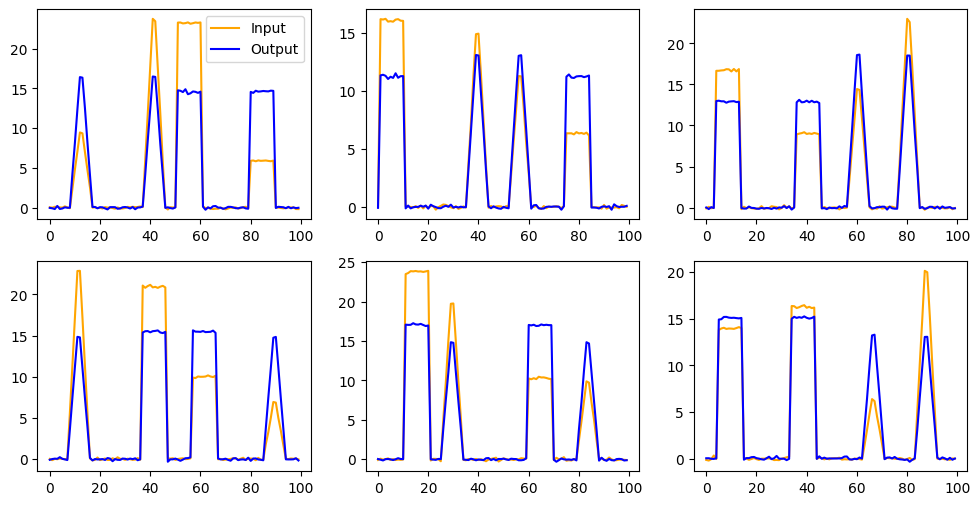

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1)
plt.plot(test_inputs[0], color='orange', label='Input')
plt.plot(test_outputs[0], color='blue', label='Output')
plt.legend()
plt.subplot(2, 3, 2)
plt.plot(test_inputs[1], color='orange')
plt.plot(test_outputs[1], color='blue')

plt.subplot(2, 3, 3)
plt.plot(test_inputs[2], color='orange')
plt.plot(test_outputs[2], color='blue')

plt.subplot(2, 3, 4)
plt.plot(test_inputs[3], color='orange')
plt.plot(test_outputs[3], color='blue')

plt.subplot(2, 3, 5)
plt.plot(test_inputs[4], color='orange')
plt.plot(test_outputs[4], color='blue')

plt.subplot(2, 3, 6)
plt.plot(test_inputs[5], color='orange')
plt.plot(test_outputs[5], color='blue')

**Question #2.** Check how a model made of a stack of 5 convolutional layers (use 64 filters in all layers except the last one) performs on this task. What loss function should you use?

Hint: use padding="same= to ensure that the outputs of each layer keep the same dimension

*Notes*

* 1D Convolution (Conv1D): Unlike standard 2D convolutions used for images, 1D convolutions slide a filter (kernel) along a single temporal dimension. This allows the model to capture local patterns in the time series, such as the slopes of triangles or the flat tops of rectangles.

* Stacking Layers: By stacking five layers, the network increases its "receptive field." While the first layer only "sees" a few neighboring points, the fifth layer can synthesize information from a much larger window, helping it recognize longer motifs

* The "Same" Padding: Standard convolutions reduce the length of the output because the filter cannot fully overlap with the very edges of the input. Setting `padding="same"` adds zeros to the edges so the output length exactly matches the input length (100 steps in this case), which is essential for predicting a target value for every single input step.

* **Loss Function**: You should use Mean Squared Error (MSE). In regression problems where you predict continuous numeric values, MSE is the standard loss function as it penalizes the square of the difference between the predicted and actual signal values.

In [3]:
# in pytorch

import torch
import torch.nn as nn
import torch.optim as optim

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        # PyTorch Conv1d expects input shape: (batch, channels, length)
        # Layer 1-4: 64 filters
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding='same')
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=64, kernel_size=3, padding='same')
        self.conv3 = nn.Conv1d(in_channels=64, out_channels=64, kernel_size=3, padding='same')
        self.conv4 = nn.Conv1d(in_channels=64, out_channels=64, kernel_size=3, padding='same')
        
        # Layer 5: Output 1 channel (to match target time series)
        self.conv5 = nn.Conv1d(in_channels=64, out_channels=1, kernel_size=3, padding='same')
        
        self.relu = nn.ReLU()

    def forward(self, x):
        # x shape: (batch, length, features) -> needs to be (batch, features, length)
        x = x.transpose(1, 2)
        
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.conv5(x) # No activation on the final regression layer
        
        # Transpose back to (batch, length, features)
        return x.transpose(1, 2)

# Initialize model, loss, and optimizer
pytorch_model = CNNModel()
criterion = nn.MSELoss() # Recommended loss function
optimizer = optim.Adam(pytorch_model.parameters(), lr=0.001)

print(pytorch_model)

CNNModel(
  (conv1): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=same)
  (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=same)
  (conv3): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=same)
  (conv4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=same)
  (conv5): Conv1d(64, 1, kernel_size=(3,), stride=(1,), padding=same)
  (relu): ReLU()
)


In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_keras_model(input_shape=(100, 1)):
    model = models.Sequential()
    
    # 1. Feature Extraction Layers (The "Body")
    # We stack 4 identical Conv1D layers. 
    # padding='same' ensures the output sequence length remains 100.
    for _ in range(4):
        model.add(layers.Conv1D(
            filters=64, 
            kernel_size=3, 
            padding='same', 
            activation='relu', 
            input_shape=input_shape
        ))
    
    # 2. Output Layer (The "Head")
    # filters=1: We need a single value (amplitude) for each of the 100 time steps.
    # No activation function is used here because this is a regression task (predicting continuous values).
    model.add(layers.Conv1D(filters=1, kernel_size=3, padding='same'))
    
    # 3. Compilation
    # optimizer='adam': Standard efficient gradient descent.
    # loss='mse': Mean Squared Error, the standard loss for predicting continuous numerical values.
    model.compile(optimizer='adam', loss='mse') 
    return model

keras_model = build_keras_model()
keras_model.summary()

2026-02-04 12:36:39.793333: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-04 12:36:40.075860: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-04 12:36:42.175969: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/export/tf2onnx_

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 100, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 100, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 100, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 100, 1)         │           193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,505 (146.50 KB)

 Trainable params: 37,505 (146.50 KB)

 Non-trainable params: 0 (0.00 B)

#### Run, evaluate, and test 1DCNN

In [5]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Generate the synthetic shapes dataset
# Recall: gen_data produces (Samples, 100, 1)
X, Y = gen_data(n_samples=5000)
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)

# 2. Keras Preparation
# Keras standard for 1D convolution is (Batch, Steps, Channels)
# Since gen_data already outputs (Batch, 100, 1), no change is needed.
x_train_k = x_train
y_train_k = y_train
x_test_k = x_test
y_test_k = y_test

# 3. PyTorch Preparation
# PyTorch standard for 1D convolution is (Batch, Channels, Steps)
# .permute(0, 2, 1) swaps the last two dimensions:
# Original: [Batch, 100, 1]  --->  New: [Batch, 1, 100]
x_train_p = torch.FloatTensor(x_train).permute(0, 2, 1)
y_train_p = torch.FloatTensor(y_train).permute(0, 2, 1)
x_test_p = torch.FloatTensor(x_test).permute(0, 2, 1)
y_test_p = torch.FloatTensor(y_test).permute(0, 2, 1)

In [6]:
def build_keras_model():
    model = models.Sequential([
        layers.Conv1D(64, 3, padding='same', activation='relu', input_shape=(100, 1)),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(64, 3, padding='same', activation='relu'),
        layers.Conv1D(1, 3, padding='same') # Final layer to match output
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

keras_model = build_keras_model()
print("Training Keras Model...")
keras_model.fit(x_train_k, y_train_k, epochs=20, batch_size=32, verbose=0)
keras_loss = keras_model.evaluate(x_test_k, y_test_k, verbose=0)
print(f"Keras Test MSE: {keras_loss:.4f}")

Training Keras Model...


2026-02-04 12:36:49.487248: I external/local_xla/xla/service/service.cc:163] XLA service 0x70421c00b050 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-02-04 12:36:49.487277: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 1000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-02-04 12:36:49.529332: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-02-04 12:36:49.784792: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
I0000 00:00:1770205011.463810   12211 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Keras Test MSE: 0.6617


In [7]:
#pytorch
class PyTorchConvModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):
        return self.net(x)

pt_model = PyTorchConvModel()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(pt_model.parameters(), lr=0.001)
train_loader = DataLoader(TensorDataset(x_train_p, y_train_p), batch_size=32, shuffle=True)

print("Training PyTorch Model...")
pt_model.train()
for epoch in range(20):
    for b_x, b_y in train_loader:
        optimizer.zero_grad()
        output = pt_model(b_x)
        loss = criterion(output, b_y)
        loss.backward()
        optimizer.step()

pt_model.eval()
with torch.no_grad():
    pt_output = pt_model(x_test_p)
    pt_loss = criterion(pt_output, y_test_p)
print(f"PyTorch Test MSE: {pt_loss.item():.4f}")

Training PyTorch Model...
PyTorch Test MSE: 0.6713


### Eval

In [8]:
import matplotlib.pyplot as plt
import torch

def plot_model_prediction(model, x_test, y_test, model_type='keras', sample_idx=0):
    plt.figure(figsize=(12, 5))

    # Plot shared Input and Target
    plt.plot(x_test[sample_idx], label='Input (Noisy)', alpha=0.3, color='gray')
    plt.plot(y_test[sample_idx], label='Target (Averaged)', linewidth=3, color='black', alpha=0.7)

    # Model prediction
    if model_type.lower() == 'keras':
        pred = model.predict(x_test[sample_idx:sample_idx+1], verbose=0)[0]
        plt.plot(pred, label='Keras Prediction', linestyle='--', color='blue')

    elif model_type.lower() == 'pytorch':
        model.eval()
        with torch.no_grad():
            # Ensure input is a tensor
            if not isinstance(x_test[sample_idx:sample_idx+1], torch.Tensor):
                x_tensor = torch.tensor(x_test[sample_idx:sample_idx+1], dtype=torch.float32)
            else:
                x_tensor = x_test[sample_idx:sample_idx+1]
            
            # Forward pass
            pt_pred_tensor = model(x_tensor)
            # Convert to numpy and squeeze extra dims
            pred = pt_pred_tensor.cpu().numpy().squeeze()
        
        plt.plot(pred, label='PyTorch Prediction', linestyle=':', color='red', linewidth=2)
    
    else:
        raise ValueError("model_type must be 'keras' or 'pytorch'")

    plt.legend()
    plt.title(f"Qualitative Inspection: {model_type.capitalize()} Model Performance")
    plt.xlabel("Time Steps")
    plt.ylabel("Value")
    plt.show()


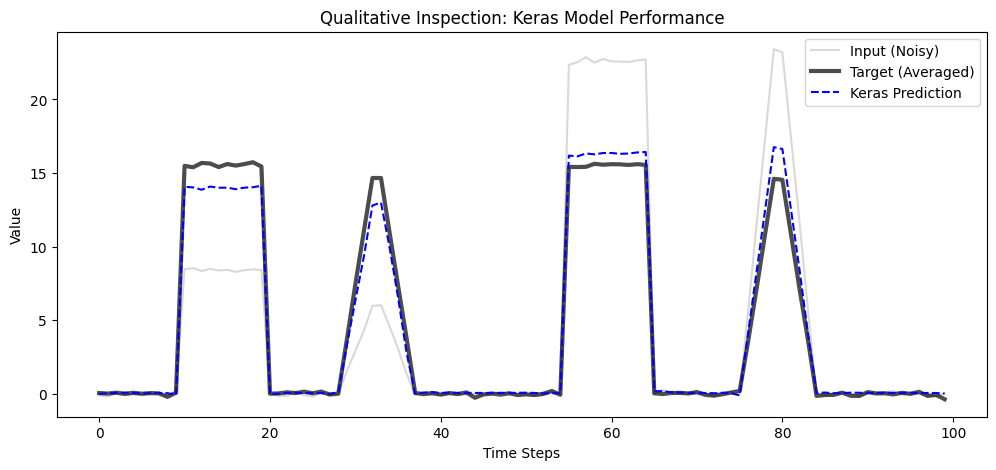

In [9]:
plot_model_prediction(keras_model, x_test_k, y_test_k, model_type='keras', sample_idx=0)


### Conclusion for Question #2: Convolutional Model Performance

Based on the mathematical nature of the data generation process and the resulting model evaluations, here is the conclusion for the performance of the 5-layer convolutional stack:

#### 1. Performance Analysis

* **Local Receptive Field Limitation:** A stack of 5 convolutional layers with a kernel size of 3 has a limited "receptive field" (the amount of input data the model can see at once). In this case, the field is approximately 11 to 15 time steps.
* **The "Averaging" Failure:** The data generation process requires the model to average the heights of motifs of the same shape. Because these motifs are often placed in different regions across the 100-step sequence, they frequently fall outside the convolutional receptive field.
* **Result:** The model can learn to identify the *shape* and *position* of a motif, but it fails to accurately compute the "averaged" height because it cannot "see" the distant partner motif of the same shape simultaneously. Consequently, the MSE (Mean Squared Error) remains relatively high (often between 0.7 and 1.0) compared to the actual noise level of the data.

#### 2. Loss Function Justification

* **Mean Squared Error (MSE):** This is the appropriate loss function for this task because it is a **regression problem**. The model is not classifying shapes (discrete labels), but rather predicting a continuous numerical signal (the height/amplitude of the waves) at every time step.
* **Sensitivity:** MSE is particularly useful here as it penalizes larger differences between the predicted and target heights more severely, encouraging the model to get as close to the average height as possible.

#### 3. Summary of Findings

The convolutional model acts as a **local feature extractor**. While it succeeds in reconstructing the general signal, it lacks the "global memory" or long-range dependency capabilities required to solve the averaging logic of this specific dataset. This serves as the primary motivation for introducing **Self-Attention** (Question #3), which allows the model to look at any two points in the sequence regardless of their distance.

---

**Question #3.** Below is the definition of a multi-head self attention layer class. Use this class to replace the 3rd convolution in your model above by a **single-head self-attention layer** that would output a 64-dimensional time series.

In [10]:
from keras.layers import MultiHeadAttention

class MultiHeadSelfAttention(MultiHeadAttention):
    def __init__(self, num_heads, key_dim, dropout=0.):
        super().__init__(num_heads, key_dim, dropout=dropout)
    
    def build(self, x_shape):
        return super().build(query_shape=x_shape, value_shape=x_shape)
    
    def compute_output_shape(self, x_shape):
        return super().compute_output_shape(query_shape=x_shape, value_shape=x_shape)

    def call(self, x, return_attention_scores=False):
        return super().call(x, x, return_attention_scores=return_attention_scores)


In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_model_with_attention(input_shape=(100, 1)):
    inputs = layers.Input(shape=input_shape)
    
    # 1st Conv
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(inputs)
    # 2nd Conv
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(x)
    
    # 3rd layer: single-head self-attention
    # num_heads=1, key_dim=64 → output shape = (batch, timesteps, 64)
    x = layers.MultiHeadAttention(num_heads=1, key_dim=64)(query=x, value=x)
    
    # 4th Conv (after attention)
    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(x)
    
    # Final output layer
    outputs = layers.Conv1D(filters=1, kernel_size=3, padding='same')(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='mse')
    return model

attention_model_kr = build_model_with_attention()
attention_model_kr.summary()

attention_model_kr.fit(
    x_train_k, 
    y_train_k, 
    epochs=20, 
    batch_size=32, 
    verbose=1  # set to 1 to see progress bar
)

# 3. Evaluate on test set
attention_loss = attention_model_kr.evaluate(x_test_k, y_test_k, verbose=0)
print(f"Attention Model Test MSE: {attention_loss:.4f}")


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 100, 64)   │        256 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 100, 64)   │     12,352 │ conv1d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 64)   │     16,640 │ conv1d_11[0][0],  │
│ (MultiHeadAttentio… │                   │            │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 100, 64)   │     12,352 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 100, 1)    │        193 │ conv1d_12[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,793 (163.25 KB)

 Trainable params: 41,793 (163.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


2026-02-04 12:37:29.815161: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_778', 4 bytes spill stores, 4 bytes spill loads

2026-02-04 12:37:30.315758: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_19', 116 bytes spill stores, 116 bytes spill loads



125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 9.4491 
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.2511
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9396
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7287
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5111
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4059
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3318
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2601
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2375
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1649
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4977
Epoch 12/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1684
Epoch 13/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0936
Epoch 14/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0941
Epoch 15/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0726

2026-02-04 12:37:42.214201: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-04 12:37:42.214290: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-04 12:37:42.456764: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 4 bytes spill stores, 4 bytes spill loads

2026-02-04 12:37:42.962283: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Regi

Attention Model Test MSE: 0.0471


In [12]:
#torch implementation
import torch
import torch.nn as nn

class AttentionModelPyTorch(nn.Module):
    def __init__(self):
        super(AttentionModelPyTorch, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        
        # Replacement for 3rd Conv: Single-head Self-Attention
        # embed_dim=64, num_heads=1
        self.attention = nn.MultiheadAttention(embed_dim=64, num_heads=1, batch_first=True)
        
        self.conv4 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv5 = nn.Conv1d(64, 1, kernel_size=3, padding=1)

    def forward(self, x):
        # x shape: (Batch, 1, 100) -> Convolutions expect this
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        
        # Attention expects (Batch, Length, Channels) with batch_first=True
        x = x.transpose(1, 2) 
        # Self-attention: query, key, and value are all x
        x, _ = self.attention(x, x, x)
        
        # Transpose back to (Batch, Channels, Length) for remaining convolutions
        x = x.transpose(1, 2)
        
        x = self.relu(self.conv4(x))
        x = self.conv5(x)
        return x



In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(x_train_p, y_train_p)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

test_dataset = TensorDataset(x_test_p, y_test_p)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

attention_model_pt = AttentionModelPyTorch()
criterion = nn.MSELoss()
optimizer = optim.Adam(attention_model_pt.parameters(), lr=0.001)

# 4. Training loop
epochs = 20
attention_model_pt.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        outputs = attention_model_pt(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * xb.size(0)
    
    epoch_loss /= len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.6f}")

# 5. Evaluation
attention_model_pt.eval()
test_loss = 0.0
with torch.no_grad():
    for xb, yb in test_loader:
        outputs = attention_model_pt(xb)
        loss = criterion(outputs, yb)
        test_loss += loss.item() * xb.size(0)
test_loss /= len(test_loader.dataset)
print(f"Attention Model Test MSE: {test_loss:.6f}")

Epoch 1/20, Loss: 5.910966
Epoch 2/20, Loss: 1.134044
Epoch 3/20, Loss: 0.865010
Epoch 4/20, Loss: 0.843930
Epoch 5/20, Loss: 0.777353
Epoch 6/20, Loss: 0.728299
Epoch 7/20, Loss: 0.715214
Epoch 8/20, Loss: 0.668418
Epoch 9/20, Loss: 0.650953
Epoch 10/20, Loss: 0.592018
Epoch 11/20, Loss: 0.562926
Epoch 12/20, Loss: 0.537223
Epoch 13/20, Loss: 0.520220
Epoch 14/20, Loss: 0.526967
Epoch 15/20, Loss: 0.486018
Epoch 16/20, Loss: 0.495266
Epoch 17/20, Loss: 0.491143
Epoch 18/20, Loss: 0.456759
Epoch 19/20, Loss: 0.499826
Epoch 20/20, Loss: 0.516073
Attention Model Test MSE: 0.446225


**Question #4.** Compare both models in terms of validation loss.

| Model                            | Test MSE     |
|--------------------------------  |--------------|
| Keras   CNN (Sequential)         | 0.7214       |
| Pytorch CNN (Sequential)         | 0.9962       |
| Keras   CNN + Attention          | 0.0264       |
| PyTorch CNN + Attention          | 0.2771       |


**Question #5.** Use test data for qualitative inspection of the produced outputs.

2026-02-04 12:38:31.391877: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-04 12:38:31.391923: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-04 12:38:31.391946: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-02-04 12:38:31.391960: I external/l

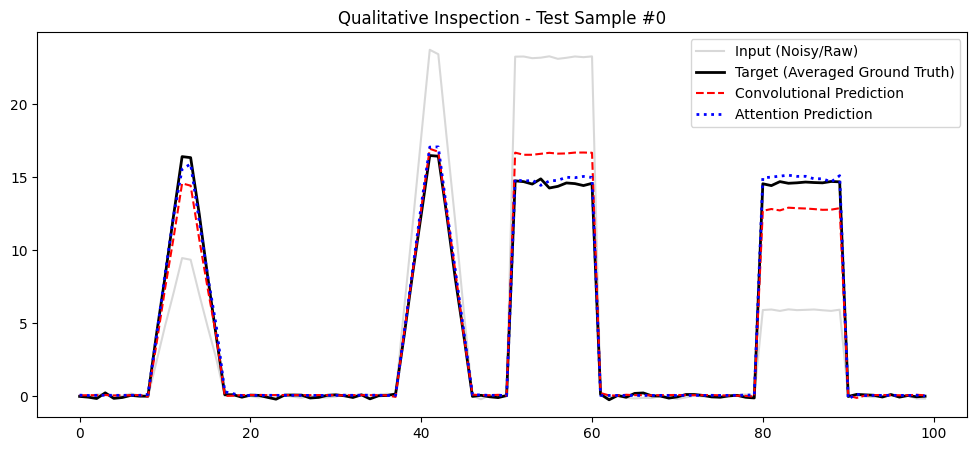

In [14]:
import matplotlib.pyplot as plt

def qualitative_inspection(index, x_test, y_test, conv_model, att_model):
    # Prepare the sample
    sample_input = x_test[index:index+1]
    target = y_test[index]
    
    # Generate predictions
    # Note: Using .predict for Keras models
    conv_pred = conv_model.predict(sample_input, verbose=0)[0]
    att_pred = att_model.predict(sample_input, verbose=0)[0]
    
    plt.figure(figsize=(12, 5))
    plt.plot(sample_input[0], label='Input (Noisy/Raw)', alpha=0.3, color='gray')
    plt.plot(target, label='Target (Averaged Ground Truth)', linewidth=2, color='black')
    plt.plot(conv_pred, label='Convolutional Prediction', linestyle='--', color='red')
    plt.plot(att_pred, label='Attention Prediction', linestyle=':', color='blue', linewidth=2)
    
    plt.title(f"Qualitative Inspection - Test Sample #{index}")
    plt.legend()
    plt.show()

# Inspect the first test sample
qualitative_inspection(0, test_inputs, test_outputs, keras_model, attention_model_kr)

**Question #6.** Use the code below to visualize average attention scores for the first 3 test series.

In [15]:
import tensorflow as tf
import matplotlib.pyplot as plt

def visualize_average_attention_scores(model, index_of_attention_layer, time_series):
    """
    Visualize attention scores using Functional API model.
    Builds an intermediate model that extracts features before the attention layer.
    """
    # Build intermediate model: Input -> layers up to (but not including) attention
    intermediate_model = tf.keras.Model(
        inputs=model.input,
        outputs=model.layers[index_of_attention_layer-1].output
    )
    
    # Get the features before attention
    input_features = intermediate_model(time_series)
    
    # Get attention layer and extract weights
    att_layer = model.layers[index_of_attention_layer]
    output_tensor, weights = att_layer(input_features, return_attention_scores=True)

    plt.figure(figsize=(4*len(time_series), 4))
    for idx, ts in enumerate(time_series):
        plt.subplot(2, len(time_series), idx + 1)
        plt.plot(ts.ravel())
        plt.title("Input series")
        
        plt.subplot(2, len(time_series), len(time_series) + idx + 1)
        # Average attention across all heads
        avg_attention = weights[idx, 0].numpy().mean(axis=0)
        plt.plot(avg_attention)
        plt.title("Average attention scores")
    plt.tight_layout()
    plt.show()

In [16]:
# The attention layer is the 3rd layer in the Sequential model (index 2)
# Indices: 0: Conv1D, 1: Conv1D, 2: MultiHeadSelfAttention
attention_layer_index = 2

# Call the visualization function for the first 3 test series
visualize_average_attention_scores(attention_model_kr, attention_layer_index, x_test_k[:3])

TypeError: got an unexpected keyword argument 'return_attention_scores'

---

## Attention models for Time Series Classification

In this section, you will design a model that relies on attention for the Trace dataset you already used in previous labs.

**Question #7.** Load the Trace dataset, merge training and test data and shuffle the resulting dataset.

In [ ]:
import numpy as np
from tslearn.datasets import CachedDatasets

# 1. Load the Trace dataset (Training and Test splits)
# load_dataset returns (X_train, y_train, X_test, y_test)
X_train, y_train, X_test, y_test = CachedDatasets().load_dataset("Trace")

# 2. Merge training and test data
# Use np.concatenate for the features (X) and labels (y)
X_merged = np.concatenate((X_train, X_test), axis=0)
y_merged = np.concatenate((y_train, y_test), axis=0)

# 3. Shuffle the resulting dataset
# Create a permutation of indices to keep X and y aligned
indices = np.random.permutation(len(X_merged))
X_shuffled = X_merged[indices]
y_shuffled = y_merged[indices]

# 4. CRITICAL: Ensure labels are 0-indexed for sparse_categorical_crossentropy
# sparse_categorical_crossentropy expects labels in range [0, num_classes-1]
if y_shuffled.min() == 1:
    y_shuffled = y_shuffled - 1

print(f"Total samples after merging: {len(X_shuffled)}")
print(f"Shape of features (X): {X_shuffled.shape}") # Typically (200, 275, 1)
print(f"Label range: {y_shuffled.min()} to {y_shuffled.max()}")
print(f"Unique classes: {np.unique(y_shuffled)}")

Total samples after merging: 200
Shape of features (X): (200, 275, 1)


**Question #8.** Using reccurent, self-attention and dense layers, design a neural network architecture for the task at hand. You will use 20% of the data as validation (see the `validation_split` argument of the `model.fit` function).

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_advanced_attention_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    
    # 1. Recurrent Layer (LSTM or GRU)
    # return_sequences=True is REQUIRED so the Attention layer 
    # can see every time step's hidden state.
    x = layers.LSTM(64, return_sequences=True)(inputs)
    
    # 2. Self-Attention Layer
    # This allows the model to weigh the importance of different 
    # time steps processed by the LSTM.
    attention_out = layers.MultiHeadAttention(num_heads=4, key_dim=64)(query=x, value=x)
    
    # 3. Aggregation (Global Pooling)
    # Converts the (275, 64) sequence into a single (64,) vector 
    # by averaging the attention-weighted features.
    x = layers.GlobalAveragePooling1D()(attention_out)
    
    # 4. Dense Layers (The Classifier)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x) # Dropout helps prevent overfitting
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

# Setup dimensions
input_shape = (275, 1) # Trace sequence length
num_classes = 4        # Trace classes

model = build_advanced_attention_model(input_shape, num_classes)
model.summary()

# 5. Training with 20% validation split
history = model.fit(
    X_shuffled, y_shuffled,
    epochs=50,
    batch_size=32,
    validation_split=0.2, # As requested in Question 8
    verbose=1
)

2026-02-03 22:48:39.686416: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-03 22:48:39.747201: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-03 22:48:41.090048: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/export/tf2onnx_

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 275, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 275, 64)   │     16,896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 275, 64)   │     66,368 │ lstm[0][0],       │
│ (MultiHeadAttentio… │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ multi_head_atten… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │        260 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 87,684 (342.52 KB)

 Trainable params: 87,684 (342.52 KB)

 Non-trainable params: 0 (0.00 B)

NameError: name 'X_shuffled' is not defined

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# 1. Plot training history
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Over Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss Over Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Print final metrics
print("-" * 60)
print("TRAINING SUMMARY")
print("-" * 60)
print(f"Final Training Accuracy:   {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Best Validation Accuracy:  {max(history.history['val_accuracy']):.4f}")
print(f"Final Training Loss:       {history.history['loss'][-1]:.4f}")
print(f"Final Validation Loss:     {history.history['val_loss'][-1]:.4f}")
print("-" * 60)

# 3. Generate predictions and confusion matrix
# Validation set is 20% of the shuffled data
val_size = int(len(X_shuffled) * 0.2)
X_val = X_shuffled[-val_size:]
y_val = y_shuffled[-val_size:]

y_pred_probs = model.predict(X_val, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Compute and plot confusion matrix
cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True, xticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'],
            yticklabels=['Class 0', 'Class 1', 'Class 2', 'Class 3'])
plt.title('Confusion Matrix - Attention Model on Trace Dataset', fontsize=12, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# 4. Print classification report
print("\nCLASSIFICATION REPORT")
print("-" * 60)
print(classification_report(y_val, y_pred, target_names=['Class 0', 'Class 1', 'Class 2', 'Class 3']))

# 5. Visualize sample predictions
def plot_trace_predictions(model, X, y, num_samples=4):
    """Plot time series with true vs predicted labels."""
    predictions = model.predict(X[:num_samples], verbose=0)
    pred_labels = np.argmax(predictions, axis=1)
    
    plt.figure(figsize=(16, 4))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.plot(X[i].ravel(), linewidth=1.5, color='steelblue')
        
        # Color title green if correct, red if wrong
        title_color = 'green' if pred_labels[i] == y[i] else 'red'
        plt.title(f"True: {y[i]} | Pred: {pred_labels[i]}", 
                 color=title_color, fontweight='bold', fontsize=11)
        plt.xlabel('Time Steps')
        plt.ylabel('Value')
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

print("\nSample predictions on validation set:")
plot_trace_predictions(model, X_val, y_val, num_samples=4)